In [1]:
import subprocess
import sys

COLAB = "google.colab" in sys.modules


def _install(package):
    if COLAB:
        ans = input(f"Install { package }? [y/n]:")
        if ans.lower() in ["y", "yes"]:
            subprocess.check_call(
                [sys.executable, "-m", "pip", "install", "--quiet", package]
            )
            print(f"{ package } installed!")


def _colab_install_missing_deps(deps):
    import importlib

    for dep in deps:
        if importlib.util.find_spec(dep) is None:
            if dep == "iris":
                dep = "scitools-iris"
            _install(dep)


deps = ["ioos_qc"]
_colab_install_missing_deps(deps)

In [2]:
import ioos_qc
print(ioos_qc.__version__)

0.1.dev812+g6f4439a2c


#   IOOS QARTOD on Glider Data
Created: 2026-10-02

Updated: 2026-10-22

During the 2026 Google Summer of Code, a project was [proposed to evaluate](https://github.com/ioos/gsoc/issues/102) the tests present in the [QARTOD glider manual](https://cdn.ioos.noaa.gov/media/2017/12/Manual-for-QC-of-Glider-Data_05_09_16.pdf), which had recently turned 10 years old. The final project was called ["Filling the gaps within the IOOS quality control schema for ocean glider data"](https://summerofcode.withgoogle.com/programs/2026/projects/bJGGUbsA) which led to a [series of investigative notebooks](https://github.com/Klankers/mau_gsoc_qartod) that did the following for tests listed within the manual:
1. Looked at the manual's description and assessed if it made sense.
2. Looked within the [IOOS QC codebase](https://github.com/ioos/ioos_qc/tree/main/ioos_qc) and assessed if it was authentic and genuine to the manual. If not, look at where the differences were and what they would do in practice.
3. Given the unknown recent activity of the manual's original authors, make additions or changes to the QARTOD toolbox to more comprehensively perform what is described in the manual.

This general procedure was done for the following tests:
1. Timing/Gap Test
2. Syntax Test
3. Location Test
4. Gross Range Test
5. Pressure Test
6. Climatology Test
14. (As ordered in the manual) Density Inversion Test

This notebook seeks to demonstrate how the tests can be used on ocean glider datasets. Unfortunately, the following tests were not assessed:

7. Spike Test
8. Rate of Change Test
9. Flat Line TEst
10. Multi-Variate Test
11. Attenuated Signal Test
12. Previous Profile Test
13. TS Curve/Space Test

As such, these tests will not be listed in this notebook unless updated at a later date.

Experimentation during the 2026 Google Summer of Code was commonly done on gliders using the [OG1 format](https://oceangliderscommunity.github.io/OG-format-user-manual/OG_Format.html). Plots, statistics, and any other outputs from this notebook are therefore entirely intended for educational purposes and are not intended to critically reflect on the dataset being used. Note that the results and settings present in this notebook may differ from those found at other institutions.

Data for this notebook is sourced from the Voice of the Ocean Foundation's ALSEAMAR *SeaExplorer* fleet, operating in the [Skagerrak](https://en.wikipedia.org/wiki/Skagerrak) between 2021 and 2026. This region is characterized by the interaction between deep, salty water from the [North Sea](https://en.wikipedia.org/wiki/North_Sea) interacting with fresh, relatively warm outflow from the [Baltic Sea](https://en.wikipedia.org/wiki/Baltic_Sea), passing through the [Danish Straits](https://en.wikipedia.org/wiki/Danish_Straits) and [Kattegat](https://en.wikipedia.org/wiki/Kattegat). This gives a temperature profile that is normally expected (warmest water at the surface), though the salinity profile is opposite of that typical in ocean gyres or open ocean (here, fresh water is on top).

The dataset to be used is [mission #109 of SeaExplorer number 044](https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/), operating for 20 days in September 2025.

This notebook is continued from part 3, which covers the Gross Range, Percentile Range and Climatology Tests. This part covers the Pressure Test and the Density Inversion Test. The setup from part 1 is repeated below, followed by the overview figure as a quick refresher.

## Load the data
Starting with imports and loading the dataset.

In [3]:
#   For loading data
import pooch
import xarray as xr

#   Contains all of our tests
from ioos_qc import qartod

#   20261022: Extracting all the plotting code.
#   The plotting helpers live next to this notebook. The file name isn't a valid module name, so load it by path.
import importlib.util
spec = importlib.util.spec_from_file_location("plotting_helpers", "2026-10-22-QARTOD-help-plot.py")
plotting_helpers = importlib.util.module_from_spec(spec)
spec.loader.exec_module(plotting_helpers)

url = "https://erddap.observations.voiceoftheocean.org/erddap/files/OG_complete_SEA044_M109/"
fname = "sea044_20250905T0639_delayed.nc"
filehash = "0bce25b78fc40bd7888a76909faa60b4f6490afd44b68a7f1f56c9d7611020ab"
#   VOTO's file hashes are not public as of September 2026. I've computed it using Python's 'hashlib'

download = pooch.retrieve(
    url=f"{url}{fname}",
    known_hash=f"sha256:{filehash}"
)
ds = xr.open_dataset(download)
ds

<xarray.Dataset> Size: 245MB
Dimensions:                             (N_MEASUREMENTS: 1699082)
Coordinates:
  * N_MEASUREMENTS                      (N_MEASUREMENTS) int64 14MB 0 ... 169...
    LATITUDE                            (N_MEASUREMENTS) float64 14MB ...
    LONGITUDE                           (N_MEASUREMENTS) float64 14MB ...
    TIME                                (N_MEASUREMENTS) datetime64[ns] 14MB ...
    DEPTH                               (N_MEASUREMENTS) float64 14MB ...
Data variables: (12/31)
    AD2CP_HEADING                       (N_MEASUREMENTS) float32 7MB ...
    AD2CP_PITCH                         (N_MEASUREMENTS) float32 7MB ...
    AD2CP_ROLL                          (N_MEASUREMENTS) float32 7MB ...
    BBP700                              (N_MEASUREMENTS) float32 7MB ...
    CHLA                                (N_MEASUREMENTS) float32 7MB ...
    DIVE_NUMBER                         (N_MEASUREMENTS) int64 14MB ...
    ...                                  ...
    SENSOR_CURRENT_PROFILERS_105527     float64 8B ...
    SENSOR_DISSOLVED_GAS_SENSORS_0095   float64 8B ...
    SENSOR_FLUOROMETERS_235280          float64 8B ...
    SENSOR_MICROSTRUCTURE_SENSORS_0496  float64 8B ...
    PROFILE_NUMBER                      (N_MEASUREMENTS) int64 14MB ...
    PROFILE_DIRECTION                   (N_MEASUREMENTS) int64 14MB ...
Attributes: (12/67)
    Conventions:                                CF-1.10, OG-1.0, Unidata Data...
    acknowledgement:                            This study used data collecte...
    agency:                                     Voice of the Ocean
    agency_role:                                contact point
    agency_role_vocabulary:                     http://vocab.nerc.ac.uk/colle...
    cdm_data_type:                              Trajectory
    ...                                         ...
    start_date:                                 20250905T0639
    basin:                                      Skagerrak
    total_dives:                                616
    dataset_id:                                 delayed_SEA044_M109
    data_url:                                   https://erddap.observations.v...
    variables:                                  ['AD2CP_HEADING', 'AD2CP_PITC...

In [4]:
from ioos_qc.qartod import QartodFlags  #   These are stored in a Class in qartod
print(dir(QartodFlags))
print(f"Unknown flag = {QartodFlags.UNKNOWN}")

#   Each flag is tied to a label and a color in the plotting helpers.
flag_style = plotting_helpers.flag_style

['FAIL', 'GOOD', 'MISSING', 'SUSPECT', 'UNKNOWN', '__class__', '__delattr__', '__dict__', '__dir__', '__doc__', '__eq__', '__firstlineno__', '__format__', '__ge__', '__getattribute__', '__getstate__', '__gt__', '__hash__', '__init__', '__init_subclass__', '__le__', '__lt__', '__module__', '__ne__', '__new__', '__reduce__', '__reduce_ex__', '__repr__', '__setattr__', '__sizeof__', '__static_attributes__', '__str__', '__subclasshook__', '__weakref__']
Unknown flag = 2


In [5]:
order = plotting_helpers.order
print(order)

[2, 1, 9, 3, 4]


In [6]:
import gsw
import numpy as np
ds["PSAL"] = gsw.SP_from_C(ds.CNDC, ds.TEMP, ds.PRES)
ds["SA"] = gsw.SA_from_SP(ds.PSAL, ds.PRES, ds.LONGITUDE, ds.LATITUDE)
ds["CT"] = gsw.CT_from_t(ds.SA, ds.TEMP, ds.PRES)
ds["SIGMA0"] = gsw.sigma0(ds.SA, ds.CT)

time = ds.TIME.values
pres = ds.PRES.values
temp = ds.TEMP.values
psal = ds.PSAL.values
sigma0 = ds.SIGMA0.values
profile = ds.PROFILE_NUMBER.values
direction = ds.PROFILE_DIRECTION.values  # 1 = descending, -1 = ascending

print(f"{time.size} measurements in {np.unique(profile).size} profiles")
print(f"{np.datetime_as_string(time[0], unit='m')} to {np.datetime_as_string(time[-1], unit='m')}")

1699082 measurements in 1232 profiles
2025-09-05T06:39 to 2025-09-25T09:24


In [7]:
#   This is a quick helper function that we can pass any flags into and get flag information out of
def flag_counts(flags, name=""):
    flags = np.ma.getdata(flags)
    parts = [
        f"{flag_style[f][0]}={np.count_nonzero(flags == f):,}" for f in order if np.any(flags == f)
    ]
    print(f"{name:<28s}" + ", ".join(parts))

In [8]:
extent = (8.8, 11.6, 57.4, 59.2)  # lon_min, lon_max, lat_min, lat_max

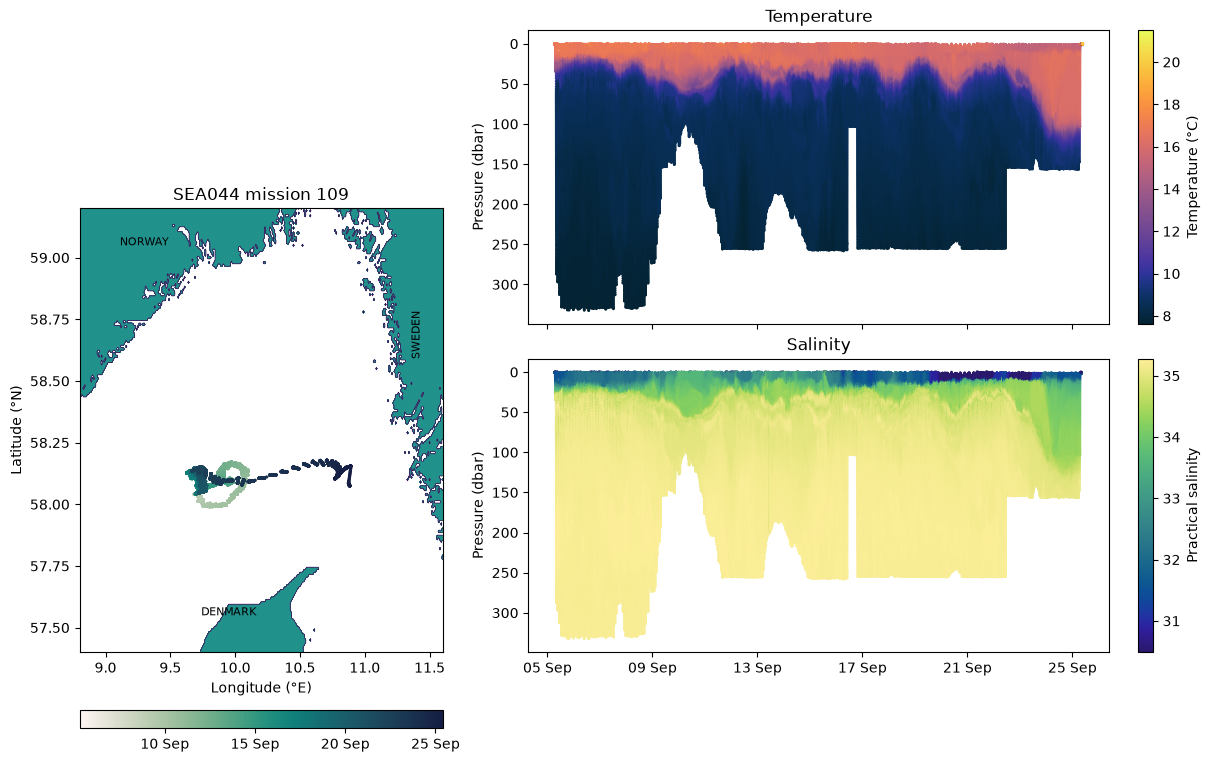

In [9]:
fig, axs = plotting_helpers.overview_figure(ds.LONGITUDE.values, ds.LATITUDE.values, time, pres, temp, psal, extent)

## Pressure Test
The pressure test works to look for a monotonic sequence during the down and upcasts of a glider. By differentiating the pressure, one can mark points as suspect if they don't move up or down by a specified amount in a given direction (`direction` is up or down, `pad` by X dbar).

Furthermore, gliders can have issues during down or upcasts where they struggle to punch through a layer. If `assess_floating` is turned on, the test starts looking at the points immediately after one that has been flagged for not going up/down by `pad` dbar and flags all the next points. If the glider doesn't hit the specified change in depth defined by the `breakout` (dbar) value, then the point is flagged.

Because it requires a direction, this test is best when assigned to an individual profile. For a more automatic version of this test (albeit, without the glider manual's description of floating gliders being flagged), see `argo.pressure_increasing_test`.

So we'll slice up our data by profile number and then pass that into our test.

In [10]:
starts = np.r_[0, np.flatnonzero(np.diff(profile)) + 1]
profile_slices = [
    slice(a, b) for a, b in zip(starts, np.r_[starts[1:], profile.size],
    strict=True)
]

#   We'll want a loop that goes through, assigning "down" or "up" based on the profile number.
def pressure_test_by_profile(pres, **kwargs):
    flags = np.full(pres.size, QartodFlags.UNKNOWN, dtype="uint8")
    for s in profile_slices:
        updown = "down" if direction[s.start] == 1 else "up"
        flags[s] = qartod.pressure_test(pres[s], updown, **kwargs)
    return flags

flags_pres = pressure_test_by_profile(pres, pad=0.01)
flags_pres_float = pressure_test_by_profile(pres, pad=0.01, assess_floating=True, breakout=0.025)
flag_counts(flags_pres, "pad=0.01:")
flag_counts(flags_pres_float, "+ assess_floating:")

pad=0.01:                   GOOD=1,620,881, MISSING=237, SUSPECT=77,964
+ assess_floating:          GOOD=1,608,308, MISSING=237, SUSPECT=90,537


As you can see above, adding the `assess_floating` parameter increases the number of suspect points by about 13,000 points. This is most evident if we plot both a downcast and an upcast next to each other. Common areas where this happens is at the bottom of a cast, when it's inflecting up, and at the end of a cast at the surface communicating with the satellite. I found a good example at casts 115 and 116, but this behavior can be seen elsewhere. If you adjust the `down` cycle to 117, you'll note how there is no transmission period present, as the glider will do multiple dives before transmitting again.

We'll zoom into the transmission period for the profile to more easily show the oscillations while transmitting prior to going up for another dive.

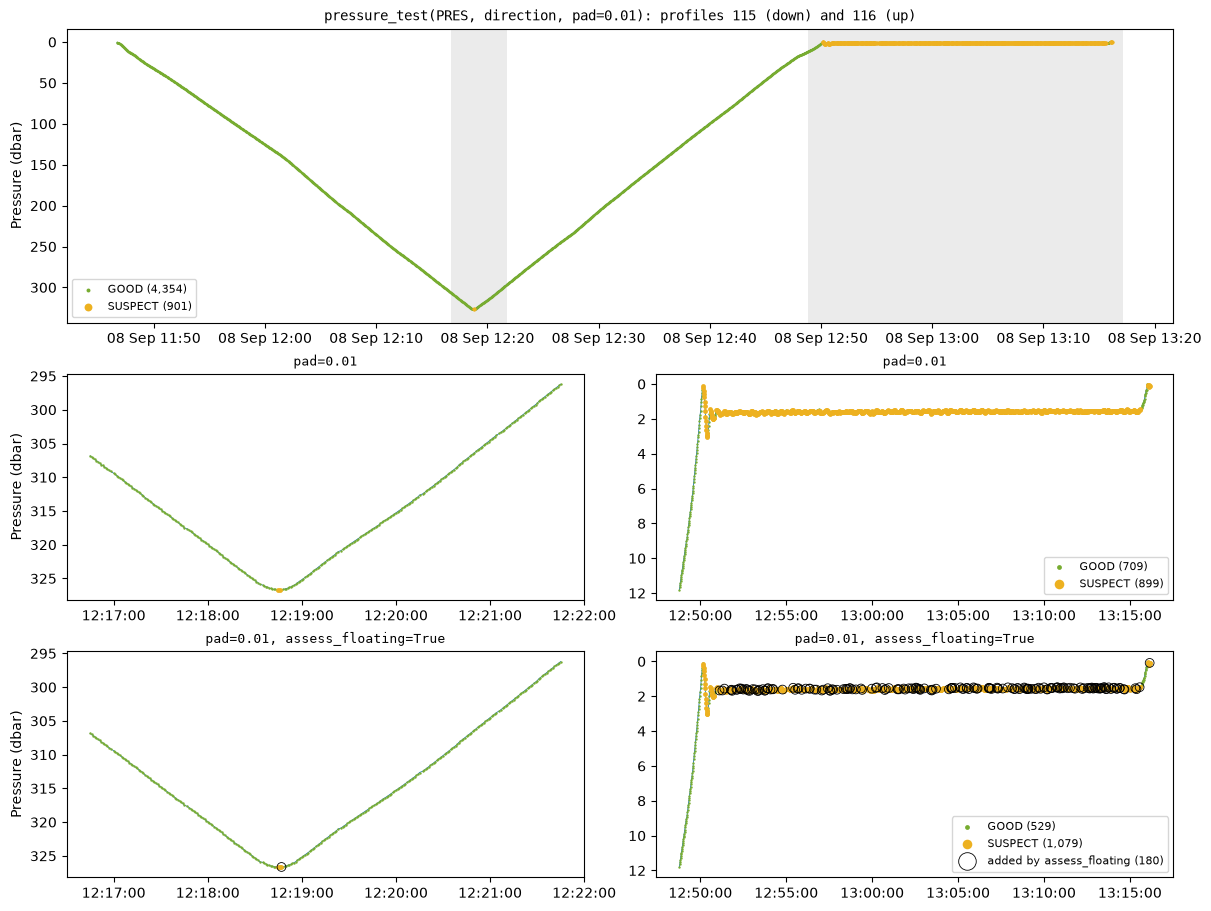

In [11]:
down = 115  #   Should be odd, the upcast that follows is plotted with it
fig, axs = plotting_helpers.pressure_cycle_figure(time, pres, profile, flags_pres, flags_pres_float, down)

Note how there are additional poitns added by the `assess_floating` designation, both at the inflection and at the surface. This could be made stricter by increasing the `breakout` requirement for the diff of the pressure.

For a better sense of this, we can look at how much of the upcast and downcast is flagged. Given we've already seen the geographic plots earlier, we know that the glider piloting behavior early in the mission was likely related to wrestling to stay on station (making that wide loop), where the glider was probably communicating more at the surface. This transitioned more into the downcast later in the mission. It's periodic - which makes sense given the glider may accomplish multiple profiles prior to transmitting with the surface.

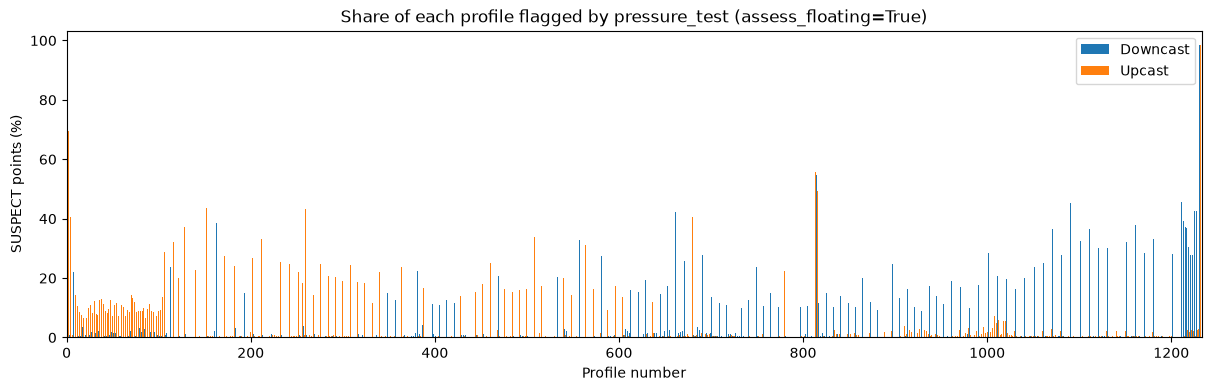

In [12]:
fig, ax = plotting_helpers.suspect_share_figure(flags_pres_float, profile_slices, profile, direction)

Given this, there are some other profiles that can be inspected. Here are some more examples that can be inspected by rerunning the earlier cell in this section:
* Transmission at the end of the upcast (orange) - 101, 115, 779
* Transmission at the beginning of the downcast (blue) - 413, 1111

## Density Inversion Test
In 99% of cases, seawater density increases with depth. The `density_inversion_test` looks for inversions - where the general rule of "density *decreases* as depth *increases*", or where the depth derivative of density is positive, is not true. Whenever this inverses (or the derivative goes negative), *or* falls below an optional threshold, both of the points are flagged.

Similar to the `gross_range_test`, this density derivative threshold accomodates for suspect and fail flags. With `ds["SIGMA0"]` or `sigma0` defined by `gsw`, we can look at what different threwsholds would potentially flag. In the docstring, 0.03 and 0.01 were suggested for suspect and fail thresholds, respectively, but it's worth looking at more. There is no reason the thresholds can't be negative - especially if changes in density are very small or data are noisy.

In [13]:
delta = np.sign(np.diff(pres)) * np.diff(sigma0)
for threshold in [0.03, 0.01, 0, -0.01, -0.03, -0.1]:
    print(f"delta < {threshold:>5}: {np.nanmean(delta < threshold) * 100:2f}% of point pairs")

delta <  0.03: 94.661820% of point pairs
delta <  0.01: 85.358556% of point pairs
delta <     0: 42.484496% of point pairs
delta < -0.01: 7.717525% of point pairs
delta < -0.03: 2.249804% of point pairs
delta <  -0.1: 0.106587% of point pairs


For this data, the depth and density is spaced differently than in the example. So the $\delta_\sigma$ or the $\delta_{depth}$ could be leading to smaller expected changes in density. Though it is concerning to see a value of 0 shows 42% of the data being flagged. Why is that?

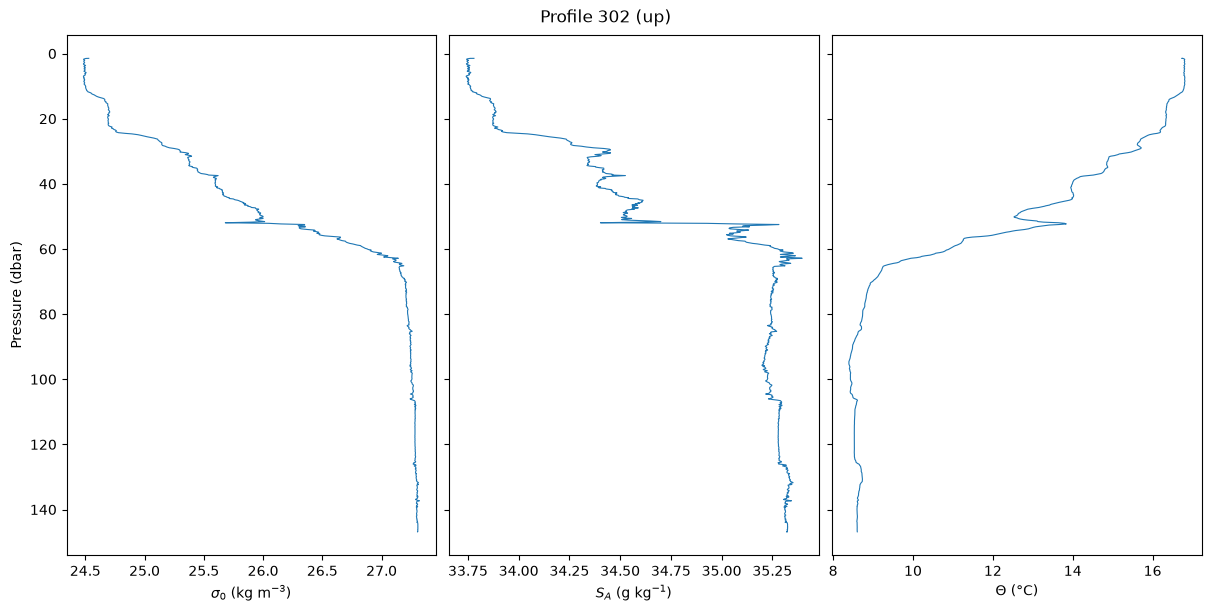

In [14]:
fig, axs = plotting_helpers.profile_panels_figure(
    pres, profile, 302,
    panels=[
        (sigma0, r"$\sigma_0$ (kg m$^{-3}$)"),
        (ds["SA"].values, r"$S_A$ (g kg$^{-1}$)"),
        (ds["CT"].values, r"$\Theta$ (°C)"),
    ],
    title="Profile 302 (up)",
)

That explains it - there are lots of micro-turbulent exceptions that may be coming from T and S used in the derivation of $\sigma_0$. This explains why so much of the data is being flagged - any kind of wobble pushes a data point *pair* into the flagged category.

Because we aren't filtering this data, we'll pass through some lenient bounds. We can see a clear spike around 55 m on this upcast, so let's assign a tolerance around -0.1 to flag that as definitely bad and a suspect value that will be between 0 and -0.1 to handle the noise that is being introduced by our $S_A$, used to derive $\sigma_0$.

In [15]:
di_suspect, di_fail = -0.05, -0.1

flags_dens = np.full(pres.size, QartodFlags.UNKNOWN, dtype="uint8")
for s in profile_slices:
    flags_dens[s] = qartod.density_inversion_test(sigma0[s], pres[s], suspect_threshold=di_suspect, fail_threshold=di_fail)
flag_counts(flags_dens, "Density inversion:")

Density inversion:          GOOD=1,665,067, MISSING=6,738, SUSPECT=23,802, FAIL=3,475


Less than 1% of the points are being flagged with these tolerances, so we're not getting all the undulations inherent to noise in the derived variables.

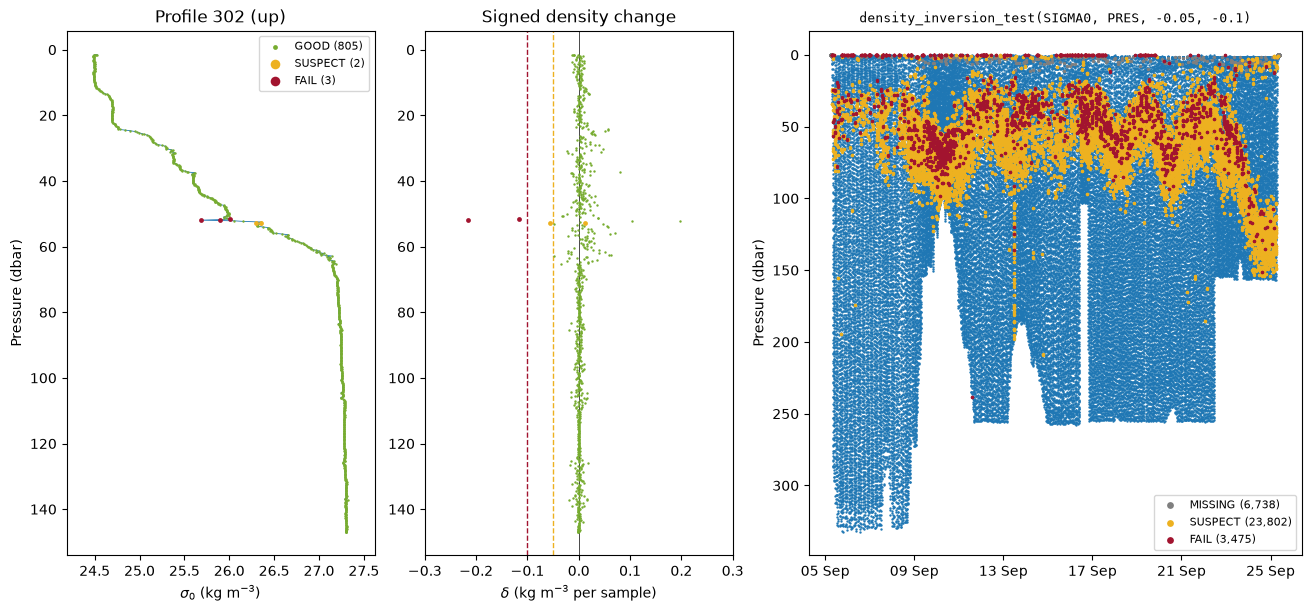

In [16]:
fig, axs = plotting_helpers.density_inversion_figure(
    time, pres, sigma0, profile, direction, profile_slices, flags_dens, 302, di_suspect, di_fail,
)

As per these results, we can see that profile 302 has three fail flags. This is because there are actually two points that go into this inversion.

In [17]:
sigma0[profile == 302][515:525]

array([26.15142867, 26.04840159, 25.68133185, 25.89739762, 26.01321673,
       25.97657509, 25.93898637, 25.93684864, 25.96887979, 26.00028115])

This is on the upcast, so we are expecting the density to *decrease*. When it goes from 25.68 to 25.89, and then to 26.01, all three points are flagged since they exceed the change of 0.1 we've assigned the test. This is reflected in the middle plot - these points lie outside of our defined tolerance for density inversion and are flagged as failing the test. There are two points flagged as suspect, and because we don't know which one is good, even the point with a positive value is flagged in yellow.

Looking at the final column, which takes all the profiles into account, we can see that this dataset is failing the test pretty consisitently with respect to other profiles. It's possible that the glider wasn't handling the salinity gradient well, or that the data should be filtered before running the test to remove some spikes and noise.